# Module 1 — Classical Computer Vision
**Assignments 1.1 (simple filters) and 1.2 (boundary detection).**

Before neural networks, people designed every image operation by hand. In this notebook you apply those operations to
**your own photos**: you see what each one measures and where it fails. Those failures are why the rest of the course
uses convolutional networks.

**How to use this notebook:** run the cells from top to bottom (*Run All*). Under every result, write one sentence on
what the operation measured, in your own words, based on what you see.

## 0. Setup — works on your computer and on Google Colab
- **On your computer:** open this notebook from your project folder, choose the kernel *Python (mai630)*, and make sure your photos are in `data/m1_images/` and your `src/classical.py` passes its tests.
- **On Colab:** run the next cell. It asks you to upload a .zip of your project folder and then your photos.

### Image credits
The three photos in `data/m1_images/` come from Wikimedia Commons. Each was resized proportionally to 800 pixels on
the longest side, with no other edits (details in `docs/image_sources.md`).
- `bottle_1.jpg`: ["Air pressure crushing a plastic bottle p1180559.jpg"](https://commons.wikimedia.org/wiki/File:Air_pressure_crushing_a_plastic_bottle_p1180559.jpg)
  by David Monniaux, via Wikimedia Commons, licensed under
  [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/). Resized from the original. **CC BY-SA:** the
  resized image and the figures in this notebook made from it are shared under the same licence.
- `bottle_2.jpg`: ["Botella pet.JPG"](https://commons.wikimedia.org/wiki/File:Botella_pet.JPG) by MdeVicente, via
  Wikimedia Commons, [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/) (public domain).
- `bottle_3.jpg`: ["Bottle of Water.jpg"](https://commons.wikimedia.org/wiki/File:Bottle_of_Water.jpg) by Jiafei Slay
  Queen, via Wikimedia Commons, [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/) (public domain).

In [1]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import files
    found = list(Path("/content").glob("*/src/classical.py"))
    if not found:
        print("Upload a .zip of your project folder (with src/classical.py inside):")
        for name, content in files.upload().items():
            Path("/content", name).write_bytes(content)
            !unzip -q -o "/content/{name}" -d /content
        found = list(Path("/content").glob("*/src/classical.py"))
    os.chdir(found[0].parents[1])
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
IMAGE_DIR = ROOT / "data" / "m1_images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

if IN_COLAB and len([p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"}]) < 3:
    print("Upload at least three photos of your own:")
    for name, content in files.upload().items():
        (IMAGE_DIR / name).write_bytes(content)

NAMES = sorted(p.name for p in IMAGE_DIR.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"})
assert len(NAMES) >= 3, f"Put at least 3 photos in {IMAGE_DIR} (found {len(NAMES)})"
print("Folder:", ROOT.name)
print("Images:", NAMES)

Folder: MAI630_Project_Starter
Images: ['bottle_1.jpg', 'bottle_2.jpg', 'bottle_3.jpg']


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from src import classical as cl


def show_row(images, titles, size=3.6):
    """Draw images side by side: 2-D arrays in grey (0 = black, 255 = white), 3-D arrays in colour."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.75))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255) if img.ndim == 2 else ax.imshow(img)
        ax.set_title(title, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()

## Part A — Assignment 1.1: simple filters
### A0. What a digital image is
**What it is.** To a computer, a photo is a table of numbers (a *matrix*). Each cell is a **pixel**. In a greyscale image
each pixel is one number from 0 (black) to 255 (white). A colour image stores three numbers per pixel: red, green
and blue.

**Watch out:** OpenCV reads the channels in the order **B, G, R**. `cl.load_rgb` converts them to R, G, B once, so the
colours look right when we draw them.

In [3]:
rgb = {n: cl.load_rgb(IMAGE_DIR / n) for n in NAMES}
for n, img in rgb.items():
    print(f"{n}: shape={img.shape} (height, width, channels)  dtype={img.dtype}  pixel(50,50) RGB={img[50, 50]}")

bottle_1.jpg: shape=(800, 363, 3) (height, width, channels)  dtype=uint8  pixel(50,50) RGB=[186 182 170]
bottle_2.jpg: shape=(800, 344, 3) (height, width, channels)  dtype=uint8  pixel(50,50) RGB=[198 145 105]
bottle_3.jpg: shape=(800, 600, 3) (height, width, channels)  dtype=uint8  pixel(50,50) RGB=[143 145 142]


**How to read it:** `shape` is the size of the table. `uint8` means whole numbers from 0 to 255. The three numbers of
a pixel are its amount of red, green and blue.

### A1. Greyscale conversion
**Why:** many classical operations need one number per pixel, not three.
**How:** a *weighted* average, `grey = 0.299 R + 0.587 G + 0.114 B`. Green weighs most because the human eye is most
sensitive to it.

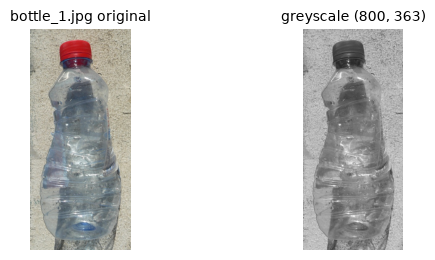

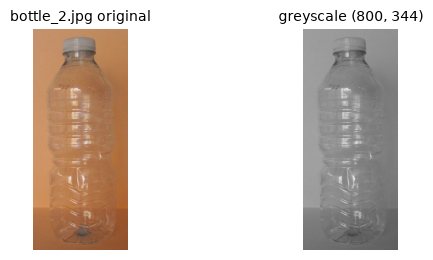

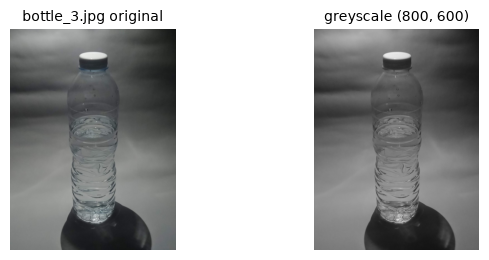

In [4]:
grey = {n: cl.to_grey(rgb[n]) for n in NAMES}
for n in NAMES:
    show_row([rgb[n], grey[n]], [f"{n} original", f"greyscale {grey[n].shape}"])

**What it measured (write after running the cell above):** Greyscale conversion removed colour information while preserving brightness differences, but it affected the images differently: the red cap in bottle_1 became dark grey, bottle_2 showed little contrast between its orange background and bottle body, and bottle_3 changed very little because it was already nearly colourless.

### A2. Brightness and contrast
**How:** `new = α · pixel + β`. β (beta) adds the same amount to every pixel, which changes **brightness**. α (alpha)
stretches the distance between dark and light, which changes **contrast**. The result is clipped to 0–255.
**Watch out:** whatever is pushed past 255 becomes pure white, and that detail is lost for good.

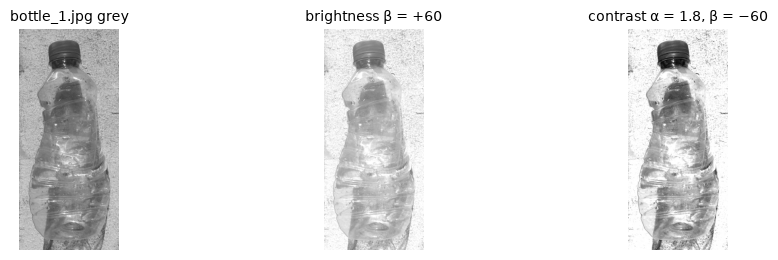

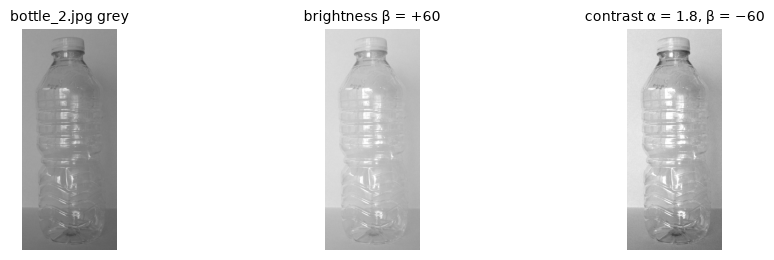

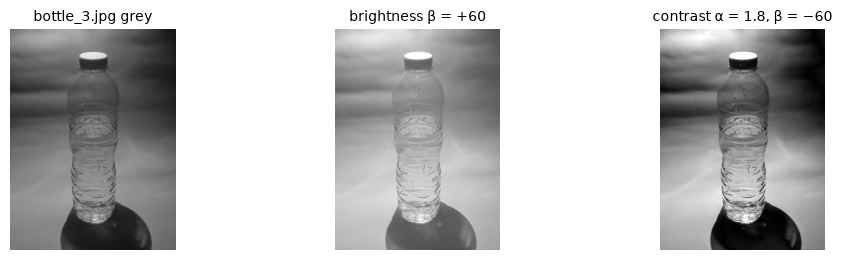

In [5]:
for n in NAMES:
    show_row([grey[n], cl.brightness_contrast(grey[n], 1.0, 60), cl.brightness_contrast(grey[n], 1.8, -60)],
             [f"{n} grey", "brightness β = +60", "contrast α = 1.8, β = −60"])

**What it measured (write after running the cell above):** Increasing brightness and contrast changed pixel intensities differently across the images: bottle_1 lost the most detail through saturation, bottle_2 showed more visible bottle ribs, and bottle_3 mainly showed increased brightness and darker shadows.

### A3. Blurring at two levels
**What it is:** each pixel is replaced by an average of its neighbours. The neighbourhood is a small square window,
the **kernel**. In a Gaussian blur the closest neighbours weigh more.
**Why:** to reduce noise, the small random errors every camera adds.
**The cost:** a larger kernel averages a wider area, so it also erases detail and edges.

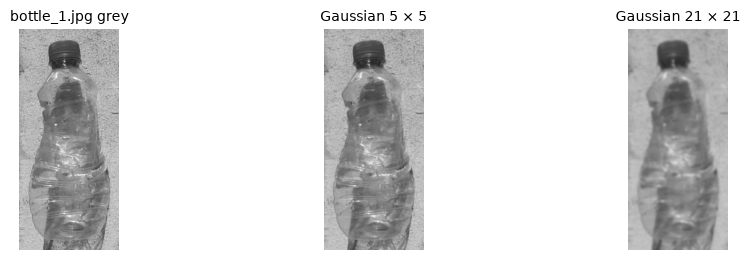

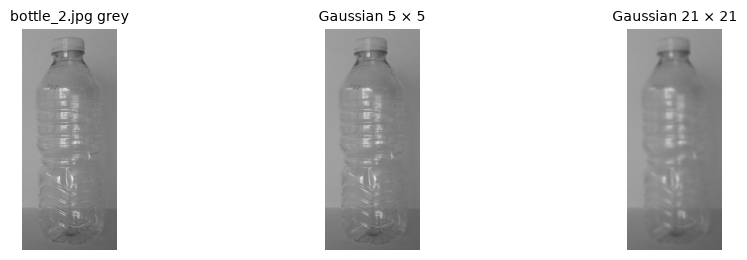

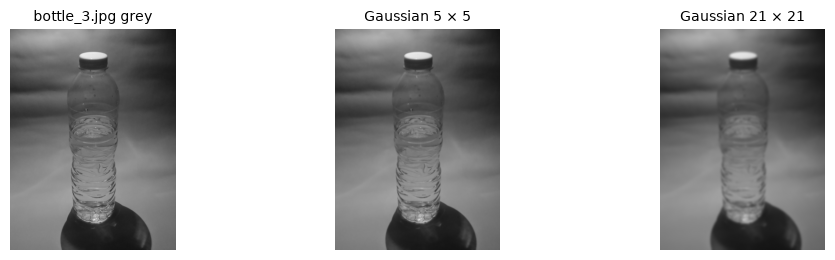

In [6]:
blur = {n: {k: cl.gaussian_blur(grey[n], k) for k in (5, 21)} for n in NAMES}
for n in NAMES:
    show_row([grey[n], blur[n][5], blur[n][21]], [f"{n} grey", "Gaussian 5 × 5", "Gaussian 21 × 21"])

**What it measured (write after running the cell above):** The 5 × 5 blur produced only subtle changes, while the 21 × 21 blur removed more fine details and texture, especially the concrete texture around bottle_1, while preserving larger features such as bottle outlines, caps, and shadows.

### A4. Thresholding
**What it is:** choose a number T. Pixels brighter than T become white and the rest black.
**Otsu's method** chooses T for you: it tries every value and keeps the one that best separates the histogram into two
groups. We blur first (5 × 5) so the noise does not drive the choice.
**How to read it:** thresholding separates *bright from dark*. It does not know what an object is.

bottle_1.jpg: Otsu chose T = 144


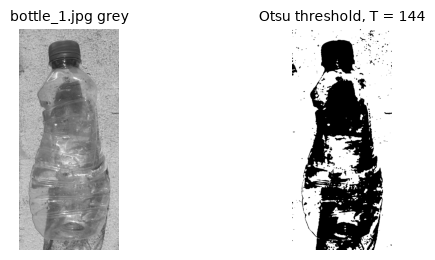

bottle_2.jpg: Otsu chose T = 135


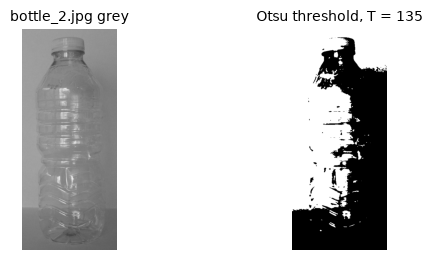

bottle_3.jpg: Otsu chose T = 96


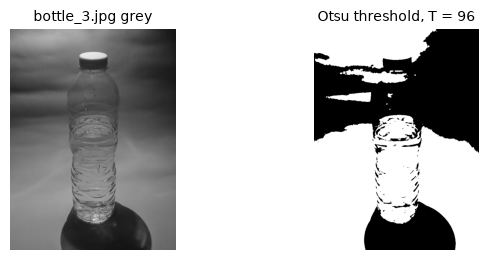

In [7]:
for n in NAMES:
    T, binary = cl.threshold_otsu(blur[n][5])
    print(f"{n}: Otsu chose T = {T}")
    show_row([grey[n], binary], [f"{n} grey", f"Otsu threshold, T = {T}"])

**What it measured (write after running the cell above):** Otsu thresholding selected thresholds of 144, 135, and 96 for the three images, but none produced a clean bottle silhouette because the resulting black-and-white separation was influenced by background brightness and lighting rather than the bottle boundaries.

### A5. A convolution with a kernel you write yourself
**What it is:** a **convolution** slides the kernel over the image. At each position it multiplies every pixel of the
window by the weight in the same place and adds the results. That sum is the new pixel.

Our kernel has 5 in the centre, −1 above, below, left and right, and 0 in the corners. The weights add up to 1, so flat
areas keep their value.

**First, on numbers you can check by hand:** the next cell applies the kernel to three tiny 5 × 5 patches: a flat region,
a dark-to-bright vertical edge, and a bright-to-dark vertical edge.

In [8]:
kernel = cl.KERNELS["sharpen"]
print(kernel, "\nsum of weights =", kernel.sum())

flat = np.full((5, 5), 100, np.uint8)
edge = np.full((5, 5), 100, np.uint8); edge[:, 3:] = 200     # dark left, bright right: a vertical edge
drop = np.full((5, 5), 200, np.uint8); drop[:, 3:] = 50      # bright left, dark right: the reverse edge
for name, patch in [("flat region", flat), ("dark-to-bright edge", edge), ("bright-to-dark edge", drop)]:
    print(f"\n{name}, input:\n{patch}")
    print(f"by hand (float, not clipped):\n{cl.convolve_by_hand(patch, kernel).round(1)}")
    print(f"apply_kernel (clipped to 0-255):\n{cl.apply_kernel(patch, kernel)}")

[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]] 
sum of weights = 1.0

flat region, input:
[[100 100 100 100 100]
 [100 100 100 100 100]
 [100 100 100 100 100]
 [100 100 100 100 100]
 [100 100 100 100 100]]
by hand (float, not clipped):
[[100. 100. 100. 100. 100.]
 [100. 100. 100. 100. 100.]
 [100. 100. 100. 100. 100.]
 [100. 100. 100. 100. 100.]
 [100. 100. 100. 100. 100.]]
apply_kernel (clipped to 0-255):
[[100 100 100 100 100]
 [100 100 100 100 100]
 [100 100 100 100 100]
 [100 100 100 100 100]
 [100 100 100 100 100]]

dark-to-bright edge, input:
[[100 100 100 200 200]
 [100 100 100 200 200]
 [100 100 100 200 200]
 [100 100 100 200 200]
 [100 100 100 200 200]]
by hand (float, not clipped):
[[100. 100.   0. 300. 200.]
 [100. 100.   0. 300. 200.]
 [100. 100.   0. 300. 200.]
 [100. 100.   0. 300. 200.]
 [100. 100.   0. 300. 200.]]
apply_kernel (clipped to 0-255):
[[100 100   0 255 200]
 [100 100   0 255 200]
 [100 100   0 255 200]
 [100 100   0 255 200]
 [100 100   0 255 200]]

bright-to

My prediction: I expect the sharpen kernel to enhance local intensity differences and make edges and fine details in the plastic bottles more pronounced. Its centre weight of 5 and four neighbouring weights of −1 should preserve uniform regions while increasing contrast around intensity transitions. I predict that the horizontal ribs on the bottle body, the ridges around the cap, and the cap grip ridges and other visible neck details will become more visible, especially where darker and brighter pixels meet. Smooth plastic surfaces and the background and its variations in brightness should remain relatively uniform, although small variations in illumination and reflections may also be amplified. I also expect the kernel to respond to edges in multiple orientations rather than detecting only horizontal ribs. Because `apply_kernel` clips negative responses to zero, some dark-side edge responses may disappear, making the result appear brighter or less balanced than the unclipped convolution output.

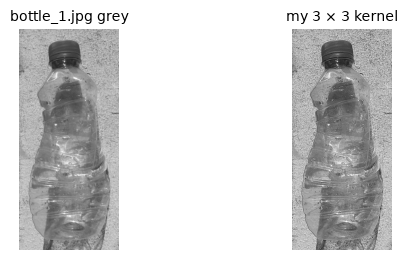

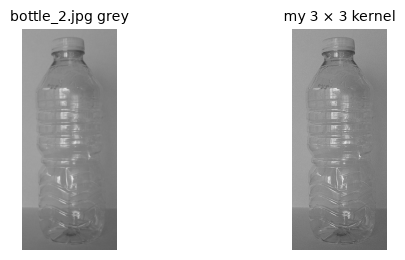

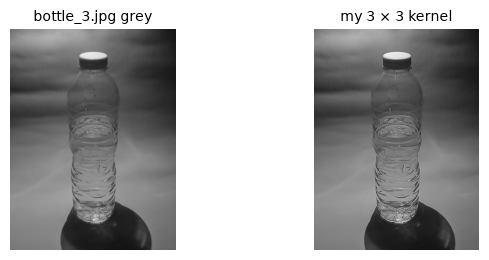

largest difference, by hand vs OpenCV: 0.0


In [9]:
for n in NAMES:
    show_row([grey[n], cl.apply_kernel(grey[n], kernel)], [f"{n} grey", "my 3 × 3 kernel"])

# Check: the same operation written out by hand gives the same numbers as OpenCV
import cv2
region = grey[NAMES[0]][30:110, 100:180]          # 80 x 80 on the red cap's edge and grip ridges of bottle_1.jpg
check = cl.convolve_by_hand(region, kernel)
ref = cv2.filter2D(region.astype(np.float32), -1, kernel, borderType=cv2.BORDER_REFLECT_101)
print("largest difference, by hand vs OpenCV:", float(np.abs(check - ref).max()))

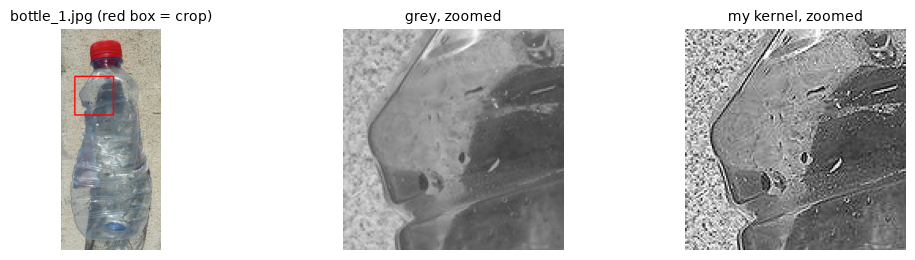

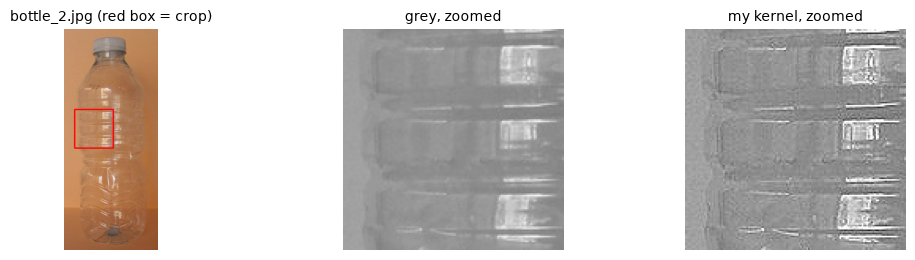

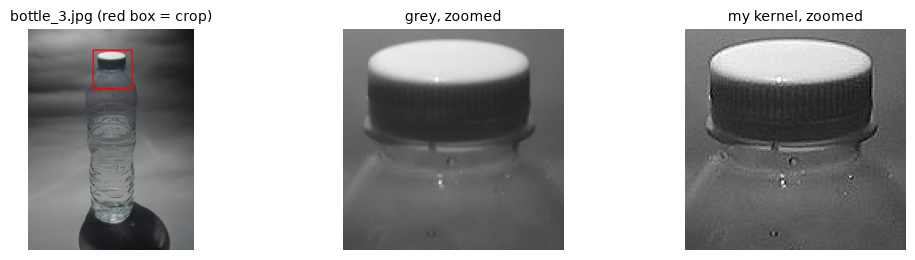

In [10]:
# Zoomed crops of bottle details. The kernel runs on the whole image first, then we cut, so the crop adds no border effects.
CROP = 140                                         # side of the square crop, in pixels
CROP_AT = {"bottle_1.jpg": (170, 50),              # (top, left): crushed folds along the left edge
           "bottle_2.jpg": (290, 40),              # ribs meeting the left edge
           "bottle_3.jpg": (75, 235)}              # cap, ridged band, neck ring and shoulder
for n in NAMES:
    h, w = grey[n].shape
    top, left = CROP_AT.get(n, ((h - CROP) // 2, (w - CROP) // 2))   # any other photo: centre crop
    where = cv2.rectangle(rgb[n].copy(), (left, top), (left + CROP, top + CROP), (255, 0, 0), 3)
    crop = np.s_[top:top + CROP, left:left + CROP]
    show_row([where, grey[n][crop], cl.apply_kernel(grey[n], kernel)[crop]],
             [f"{n} (red box = crop)", "grey, zoomed", "my kernel, zoomed"])

**What it measured (write after running the cell above):** The sharpening kernel amplified local edges and texture, making bottle folds, ribs, cap details, and droplets more pronounced, but it also amplified background texture in bottle_1 and produced clipped pixel values at both 0 and 255.

## Part B — Assignment 1.2: boundary detection
**What an edge is:** a place where the brightness **changes** quickly, not a colour. To find change we compare
neighbouring pixels. Mathematically that is a **derivative**. All three operators use the 5 × 5-blurred greyscale, so
they see the same input.

### B1. Sobel — the first derivative
Two 3 × 3 kernels estimate the change from left to right (Gx) and from top to bottom (Gy). The magnitude
√(Gx² + Gy²) says how strong the change is, in any direction.

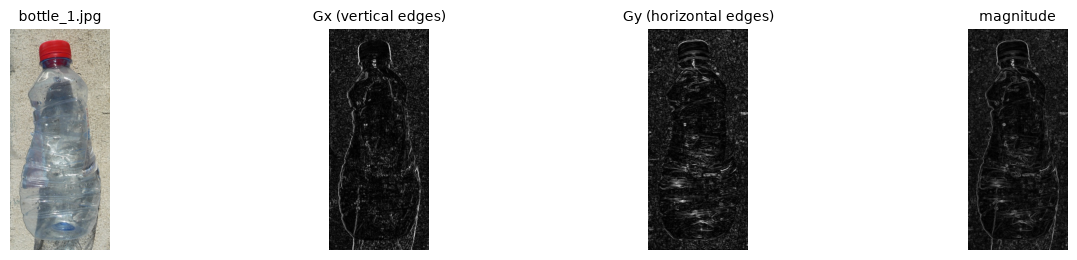

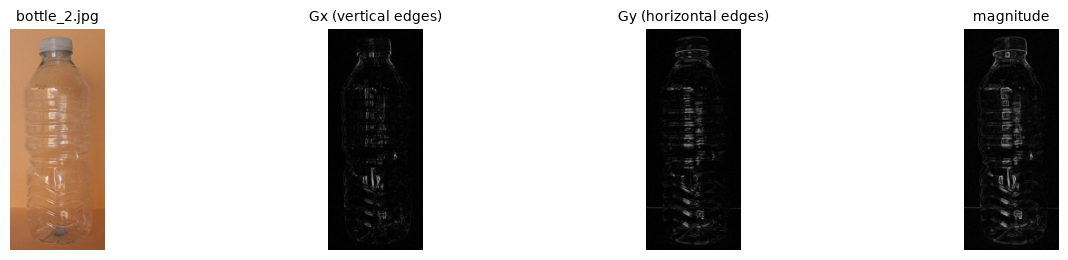

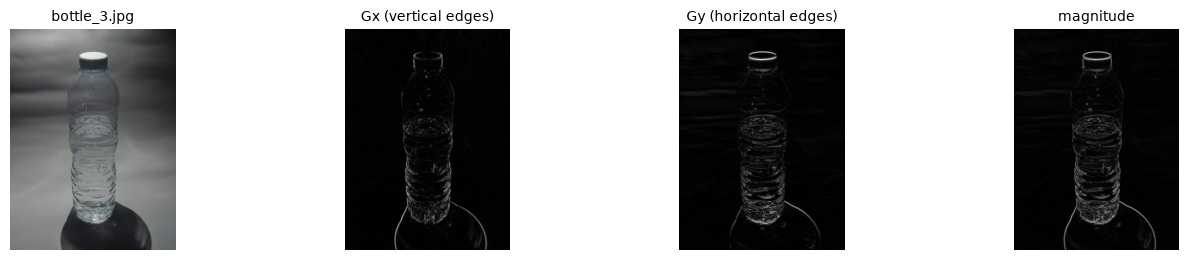

In [11]:
sobel_mag = {}
for n in NAMES:
    gx, gy, sobel_mag[n] = cl.sobel(blur[n][5])
    show_row([rgb[n], cv2.convertScaleAbs(gx), cv2.convertScaleAbs(gy), sobel_mag[n]],
             [n, "Gx (vertical edges)", "Gy (horizontal edges)", "magnitude"])

**What it measured (write after running the cell above):** Sobel detects brightness changes in both horizontal and vertical directions. In all three images, the vertical gradient (Gy) was stronger than the horizontal gradient (Gx), highlighting horizontal features such as ribs, folds, and cap edges. However, concrete texture, highlights, and shadows also produced strong responses, while the transparent bottle outline was less visible. This shows that Sobel detects intensity changes but cannot reliably distinguish bottle boundaries from background details.

### B2. Laplacian — the second derivative
It measures where the *change itself* changes, in every direction at once. It reacts very strongly to fine texture
and noise. That is why we blur first.

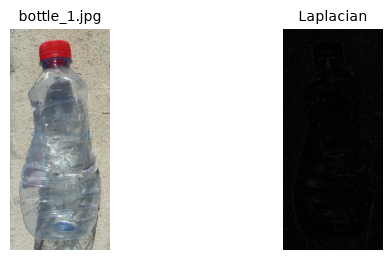

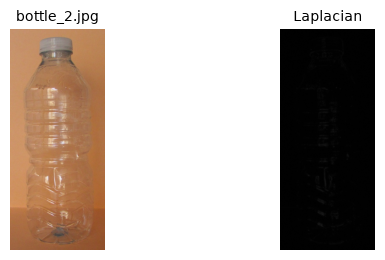

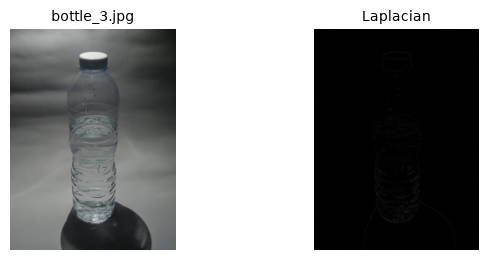

In [12]:
lap = {n: cl.laplacian(blur[n][5]) for n in NAMES}
for n in NAMES:
    show_row([rgb[n], lap[n]], [n, "Laplacian"])

**What it measured (write after running the cell above):** The Laplacian measured rapid intensity changes in all directions; it stayed near zero in flat areas and smooth gradients but responded strongly to sharp details such as bottle ribs and cap edges. In bottle_1, the concrete texture produced a response comparable to the bottle edge, while the transparent outline in bottle_2 was barely detected. The operator also produced double responses around some edges because of its second-derivative behavior. Its values were mostly below 20 on the 0–255 display scale, so the resulting figures appeared relatively dark.

### B3. Canny at three pairs of thresholds
Canny works in four steps:
1. blur;
2. compute the gradient (as Sobel does);
3. keep only the thin ridge of each edge;
4. apply **two thresholds**: pixels above `high` are edges, pixels below `low` are discarded, and pixels in between
   are kept only if they connect to a strong edge.

With two thresholds, a weak stretch of an edge survives when it continues a strong one.

bottle_1.jpg edge pixels: {(30, 90): 51450, (100, 200): 5534, (200, 400): 69}


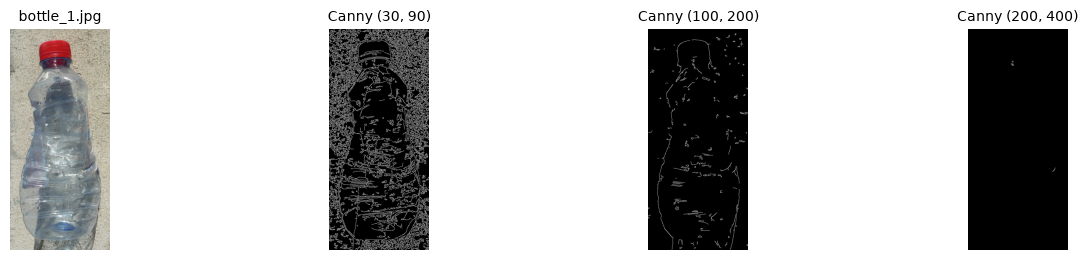

bottle_2.jpg edge pixels: {(30, 90): 7061, (100, 200): 1494, (200, 400): 0}


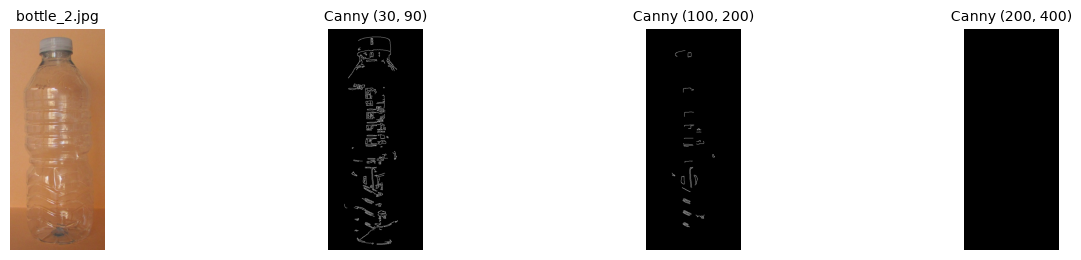

bottle_3.jpg edge pixels: {(30, 90): 9989, (100, 200): 3271, (200, 400): 16}


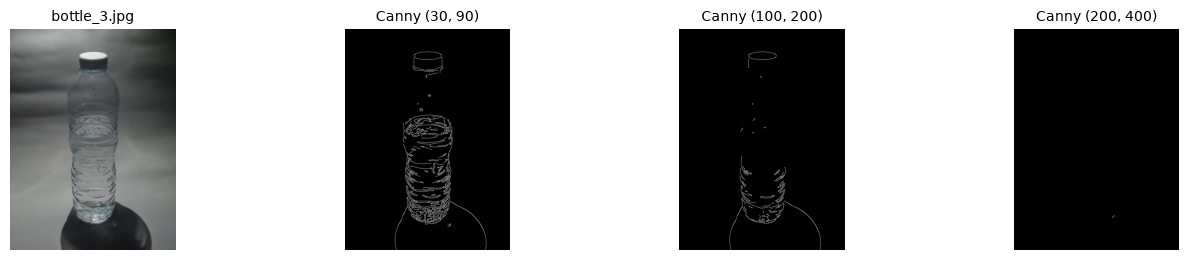

In [13]:
PAIRS = [(30, 90), (100, 200), (200, 400)]
canny = {n: {p: cl.canny(blur[n][5], *p) for p in PAIRS} for n in NAMES}
for n in NAMES:
    print(n, "edge pixels:", {p: cl.edge_pixels(canny[n][p]) for p in PAIRS})
    show_row([rgb[n]] + [canny[n][p] for p in PAIRS], [n] + [f"Canny {p}" for p in PAIRS])

**What it measured (write after running the cell above):** Canny detected fewer edges as the threshold pair increased from (30, 90) to (100, 200) and (200, 400). At lower thresholds, concrete texture in bottle_1 generated many false edge responses, while higher thresholds reduced this noise. In bottle_3, the threshold pair (100, 200) preserved important features, including 72% of the bottle outline, the cap rim, and 100% of the shadow, while the pair (200, 400) removed these features almost entirely. However, bottle_2's transparent outline was not detected at any threshold because its strongest gradient reached only 66, below all three high thresholds (90, 200, and 400). This resulted in incomplete or broken outlines, showing that Canny's performance depends strongly on threshold selection and edge contrast.

### B4. The three operators side by side

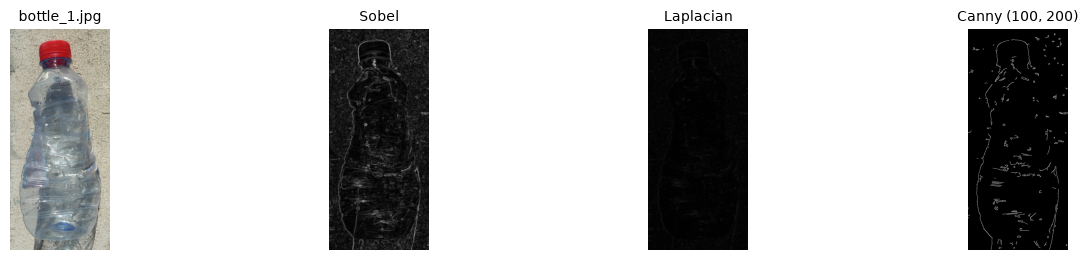

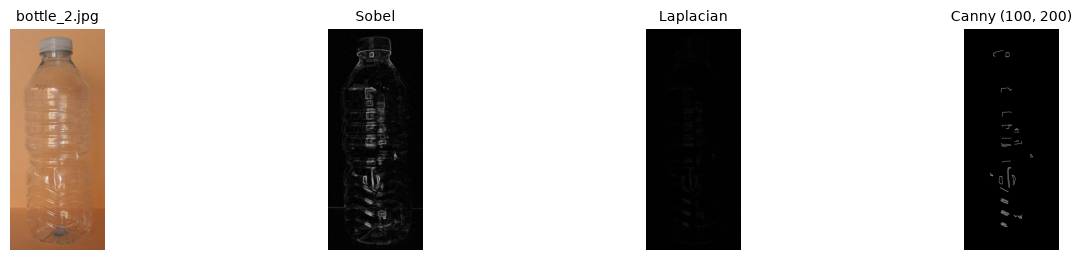

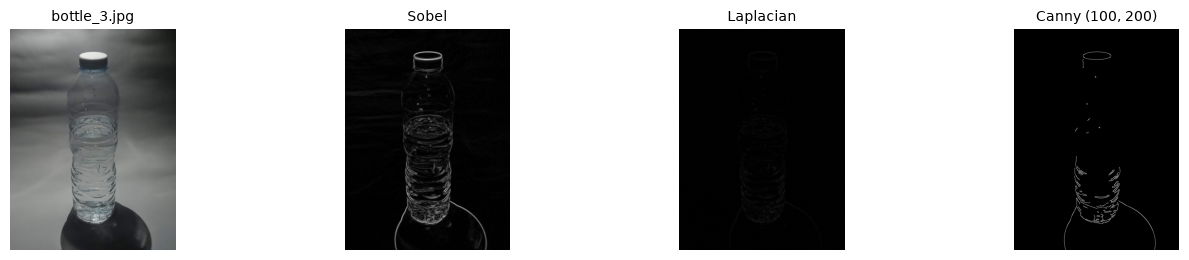

In [14]:
for n in NAMES:
    show_row([rgb[n], sobel_mag[n], lap[n], canny[n][(100, 200)]], [n, "Sobel", "Laplacian", "Canny (100, 200)"])

### B5. One image where the operators disagree — and why

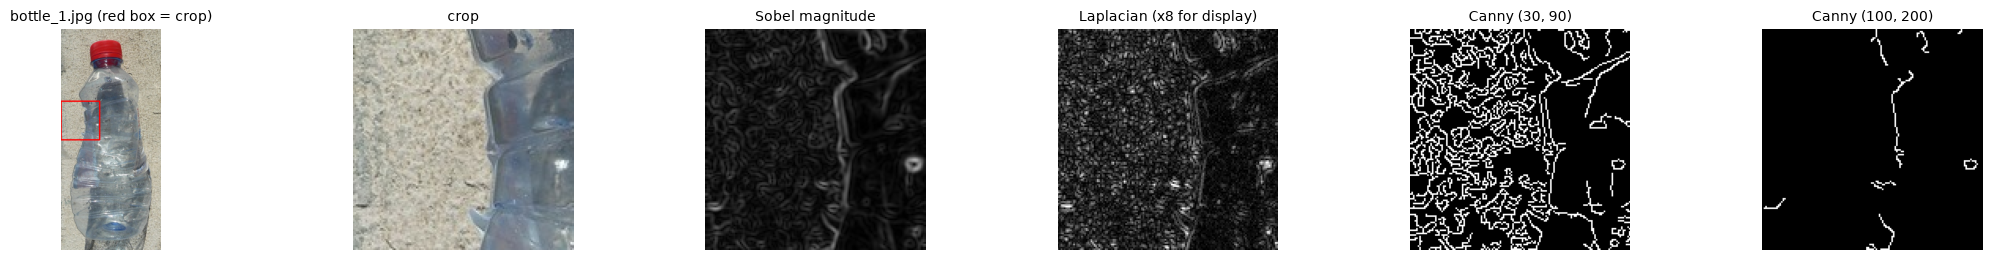

concrete (x 5-65)            Sobel  22.8   Laplacian  5.3   Canny % (30, 90): 27.2  (100, 200):  0.2  (200, 400):  0.0
bottle edge (x 78-95)        Sobel  32.6   Laplacian  5.2   Canny % (30, 90): 16.0  (100, 200):  5.1  (200, 400):  0.0


In [15]:
# B5: bottle_1, concrete texture (left of the crop) next to the bottle's left edge (right of the crop)
n = "bottle_1.jpg"
x1, y1, x2, y2 = 0, 260, 140, 400                    # crop corners: (x1, y1) top-left, (x2, y2) bottom-right
crop = np.s_[y1:y2, x1:x2]
where = cv2.rectangle(rgb[n].copy(), (x1, y1), (x2, y2), (255, 0, 0), 3)
show_row([where, rgb[n][crop], sobel_mag[n][crop], cv2.convertScaleAbs(lap[n][crop], alpha=8),
          canny[n][(30, 90)][crop], canny[n][(100, 200)][crop]],
         [f"{n} (red box = crop)", "crop", "Sobel magnitude", "Laplacian (x8 for display)",
          "Canny (30, 90)", "Canny (100, 200)"])

# Mean Sobel and Laplacian response, and the % of pixels Canny marks as edges, inside each region
for label, cols in [("concrete (x 5-65)", np.s_[5:65]), ("bottle edge (x 78-95)", np.s_[78:95])]:
    region = np.s_[y1:y2, cols]
    print(f"{label:28s} Sobel {sobel_mag[n][region].mean():5.1f}   Laplacian {lap[n][region].mean():4.1f}   Canny % "
          + "  ".join(f"{p}: {(canny[n][p][region] > 0).mean() * 100:4.1f}" for p in PAIRS))

**What it measured (write after running the cell above):** In the bottle_1 crop, the operators disagreed about which intensity changes represented the bottle boundary rather than background texture. Sobel responded more strongly to the bottle-edge region than to the concrete (32.6 versus 22.8), while the Laplacian produced nearly equal responses in both regions (5.2 versus 5.3). Canny at (30, 90) detected more concrete texture than bottle-edge pixels (27.2% versus 16.0%), but at (100, 200) it suppressed most of the texture (0.2%) while retaining more edge pixels (5.1%). This happens because Sobel and the Laplacian respond to local intensity changes without distinguishing texture from object boundaries, whereas Canny uses thresholding and edge connectivity to select stronger, connected responses. Although (100, 200) gives a cleaner result, the outline remains broken. These findings illustrate the behavior of the operators in one selected crop, rather than establishing a general rule.

### B6. One image or region where every operator fails — and what defeats them

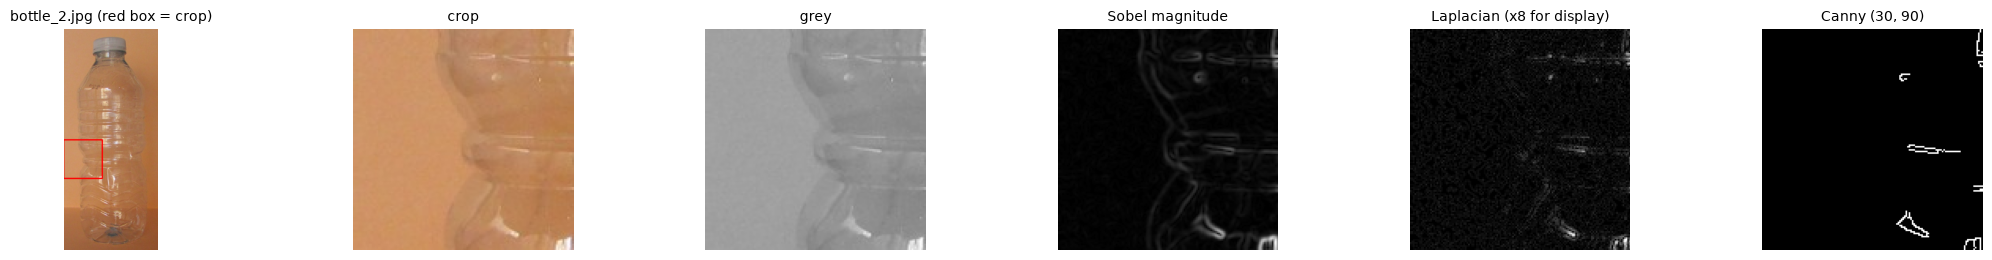

orange background (x 5-45)   Sobel   3.5   Laplacian  1.1   Canny % (30, 90):  0.0  (100, 200):  0.0  (200, 400):  0.0
bottle edge (x 55-75)        Sobel  10.2   Laplacian  1.4   Canny % (30, 90):  0.0  (100, 200):  0.0  (200, 400):  0.0
grey along row 470, x 0 to 135 (every 5 px): [163, 163, 161, 161, 158, 160, 161, 159, 161, 160, 160, 161, 158, 158, 150, 153, 154, 150, 151, 149, 151, 155, 154, 146, 141, 140, 138, 136]


In [16]:
# B6: bottle_2, the clear bottle's left edge against the orange background
n = "bottle_2.jpg"
x1, y1, x2, y2 = 0, 400, 140, 540                    # crop corners: (x1, y1) top-left, (x2, y2) bottom-right
crop = np.s_[y1:y2, x1:x2]
where = cv2.rectangle(rgb[n].copy(), (x1, y1), (x2, y2), (255, 0, 0), 3)
show_row([where, rgb[n][crop], grey[n][crop], sobel_mag[n][crop], cv2.convertScaleAbs(lap[n][crop], alpha=8),
          canny[n][(30, 90)][crop]],
         [f"{n} (red box = crop)", "crop", "grey", "Sobel magnitude", "Laplacian (x8 for display)", "Canny (30, 90)"])

# Mean Sobel and Laplacian response, and the % of pixels Canny marks as edges, inside each region
for label, cols in [("orange background (x 5-45)", np.s_[5:45]), ("bottle edge (x 55-75)", np.s_[55:75])]:
    region = np.s_[y1:y2, cols]
    print(f"{label:28s} Sobel {sobel_mag[n][region].mean():5.1f}   Laplacian {lap[n][region].mean():4.1f}   Canny % "
          + "  ".join(f"{p}: {(canny[n][p][region] > 0).mean() * 100:4.1f}" for p in PAIRS))
print("grey along row 470, x 0 to 135 (every 5 px):", grey[n][470, 0:140:5].tolist())

**What it measured (write after running the cell above):** In the bottle_2 crop, the operators failed to detect the transparent bottle boundary reliably because its brightness contrast against the orange background was very weak. Along row 470, the grey value drops by only about 10 levels, from approximately 160 in the background to 150 near the outline. Canny detected 0% of the bottle-edge region at all three threshold pairs, while the Laplacian produced nearly equal mean responses in the edge and background regions (1.4 versus 1.1). Sobel responded more strongly near the edge (10.2 versus 3.5), but the response remained weak relative to the image's strongest gradient. The boundary is visible in colour but becomes difficult to distinguish in greyscale because the transparent plastic allows the background colour to show through. This example illustrates how low brightness contrast and greyscale conversion can limit intensity-based edge detection in one selected region.

## Short written comparison

**What it measured (write after running the cell above):** All three operators measure changes in image intensity rather than recognizing objects, so they respond to texture, highlights, and shadows as well as to bottle boundaries. Sobel measures first-order gradients and shows the strength and direction of intensity changes, but it also responds strongly to background texture. The Laplacian measures second-order changes and highlights sharp details, yet it responds similarly to concrete texture and bottle edges and can produce double responses around boundaries. Canny combines gradient detection, non-maximum suppression, and threshold-based edge tracking to produce thinner edges, but its results depend heavily on the chosen thresholds and can remain incomplete. In B5, the low threshold pair detected more concrete texture than bottle-edge pixels, while the higher pair suppressed most of that texture but retained only a broken outline. In B6, the transparent bottle boundary was barely visible in greyscale, and none of the operators detected it reliably. Overall, these experiments show the trade-off between detecting weak edges and suppressing unwanted responses: no single hand-designed operator or threshold setting reliably isolates every bottle boundary across these images.